# Lonta Home-Service Demand Study — 2023 AHS, v1.0

## Context & Methods
Original secondary analysis of the pinned DataLumos V2 archival copy, with Census/HUD
definitions and 183 primary-workbook control comparisons. Direct Census-origin binary
equality is not asserted. Canonical: https://lonta.io/research/home-service-demand/.
Prepared with Codex, without original client observations or independent/human-review claims.

All occupied owner homes, including no-project homes; preceding 24 months at the 2023
interview. Professional means most work outside household, not verified paid invoices.
Reported nominal costs include known zero and exclude unknown amounts. Pointwise 90%
normal intervals use 160 Fay BRR replicates; no multiplicity correction. IQRs describe
distribution spread, not uncertainty. Frozen bins/model are in the original plan.


## Data
Download the cited archive yourself. Its household/project CSV hashes are checked; no raw rows or IDs are displayed or redistributed.

In [1]:
from pathlib import Path
import os, json
import pandas as pd
from IPython.display import display, Image
from reproduce import run
ARCHIVE=os.environ.get('LONTA_AHS_ARCHIVE','source/DataLumos-217661-V2-AHS-2023-National-PUF.zip')
data=run(ARCHIVE,'results')
print('Owner housing-unit rows:', data['ownerHousingUnitRows'], '| Source project rows:', data['projectRows'])
print('Primary controls:',data['controls']['passed'],'/',data['controls']['comparisons'],'passed')


{
  "comparisons": 183,
  "passed": 183,
  "failed": []
}


Owner housing-unit rows: 28192 | Source project rows: 44689
Primary controls: 183 / 183 passed


## Results
All eight prespecified categories appear. Shares have separate count/spending denominators; cost ranges are not current quotes.

In [2]:
summary=pd.read_csv('results/categories.csv')
display(summary[['category','homes_per1000','homes_lower90','homes_upper90']].round(2))
display(summary[['category','professional_project_pct','professional_spending_pct','difference_pp','difference_lower90','difference_upper90']].round(2))
display(summary[['category','professional_known_cost_rows','cost_q1','cost_median','cost_q3','cost_median_lower90','cost_median_upper90']].round(2))


,category,homes_per1000,homes_lower90,homes_upper90
0,Insulation,20.13,18.37,21.89
1,Interior water pipes,26.44,24.46,28.41
2,Plumbing fixtures,60.01,57.16,62.87
3,Electrical wiring / panels,52.08,49.26,54.90
4,Central A/C,69.27,66.43,72.12
5,Built-in heating,59.65,57.12,62.18
6,Septic tanks,5.45,4.61,6.29
7,Water heaters,59.28,56.86,61.71


,category,professional_project_pct,professional_spending_pct,difference_pp,difference_lower90,difference_upper90
0,Insulation,57.19,79.06,21.87,18.16,25.58
1,Interior water pipes,63.98,89.35,25.37,22.04,28.70
2,Plumbing fixtures,52.55,74.83,22.27,19.43,25.11
3,Electrical wiring / panels,68.58,89.79,21.21,18.97,23.45
4,Central A/C,88.32,91.20,2.88,1.91,3.85
5,Built-in heating,86.49,92.02,5.54,3.96,7.11
6,Septic tanks,86.39,89.95,3.56,-4.08,11.20
7,Water heaters,65.53,80.67,15.14,13.61,16.67


,category,professional_known_cost_rows,cost_q1,cost_median,cost_q3,cost_median_lower90,cost_median_upper90
0,Insulation,588,1000.0,2000.0,3500.0,1649.14,2350.86
1,Interior water pipes,785,500.0,1600.0,4000.0,1294.48,1905.52
2,Plumbing fixtures,1734,400.0,860.0,2000.0,778.50,941.50
3,Electrical wiring / panels,1497,550.0,1500.0,3400.0,1431.19,1568.81
4,Central A/C,2050,4000.0,6500.0,9500.0,5873.12,7126.88
5,Built-in heating,1764,2000.0,4500.0,7000.0,4395.97,4604.03
6,Septic tanks,126,2000.0,4500.0,9800.0,3125.29,5874.71
7,Water heaters,1847,800.0,1300.0,2000.0,1206.23,1393.77


### Housing vintage
Raw group rates and descriptive income/division-adjusted associations. Suppressed cells remain unknown, not zero. Equipment stock, housing type and exposure time are not controlled. These are not individual predictions or causal effects.

In [3]:
display(pd.DataFrame(data['vintage'])[['category','vintage','estimate','lower','upper','suppressed']].round(2))
display(pd.DataFrame(data['adjusted'])[['category','vintage','estimate','lower','upper','suppressed']].round(2))


,category,vintage,estimate,lower,upper,suppressed
0,Insulation,pre_1980,25.08,22.67,27.49,False
1,Insulation,1980_1999,18.44,15.74,21.15,False
2,Insulation,2000_or_later,12.34,9.54,15.14,False
3,Interior water pipes,pre_1980,33.33,30.25,36.41,False
4,Interior water pipes,1980_1999,26.70,23.27,30.12,False
5,Interior water pipes,2000_or_later,12.88,10.31,15.45,False
6,Plumbing fixtures,pre_1980,66.76,62.96,70.56,False
7,Plumbing fixtures,1980_1999,60.56,55.26,65.86,False
8,Plumbing fixtures,2000_or_later,46.44,41.50,51.39,False
9,Electrical wiring / panels,pre_1980,62.29,58.37,66.21,False


,category,vintage,estimate,lower,upper,suppressed
0,Insulation,1980_1999,-7.44,-10.69,-4.19,False
1,Insulation,2000_or_later,-15.11,-18.57,-11.66,False
2,Interior water pipes,1980_1999,-8.31,-12.43,-4.20,False
3,Interior water pipes,2000_or_later,-23.59,-27.99,-19.20,False
4,Plumbing fixtures,1980_1999,-7.77,-14.16,-1.38,False
5,Plumbing fixtures,2000_or_later,-24.14,-29.89,-18.39,False
6,Electrical wiring / panels,1980_1999,-14.14,-19.69,-8.58,False
7,Electrical wiring / panels,2000_or_later,-34.64,-41.38,-27.90,False
8,Central A/C,1980_1999,27.14,20.06,34.21,False
9,Central A/C,2000_or_later,3.01,-3.79,9.80,False


### Reusable figures
The same population and window travel with each figure. Numerical tables above provide an accessible reading of the charts.

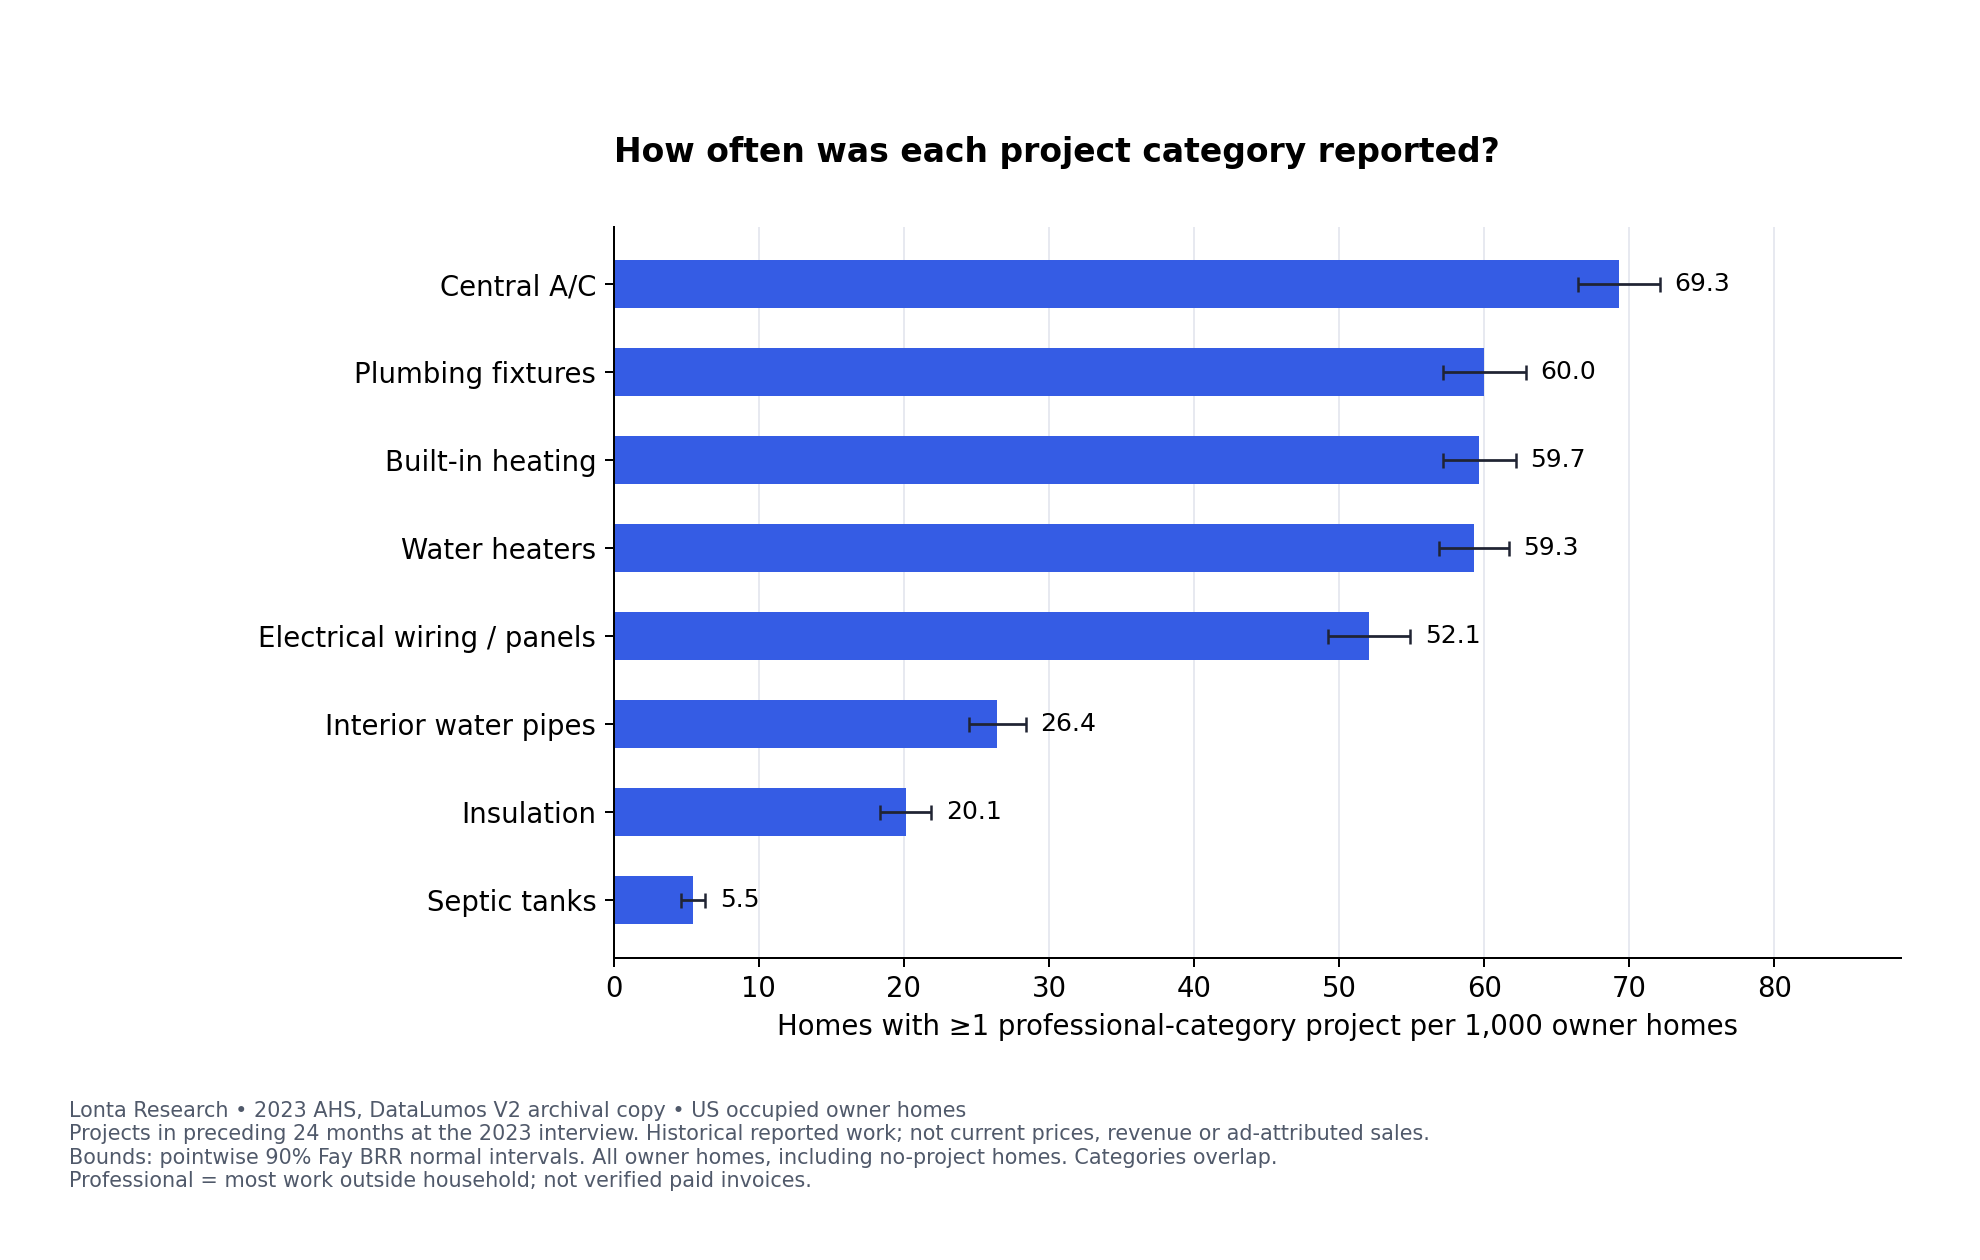

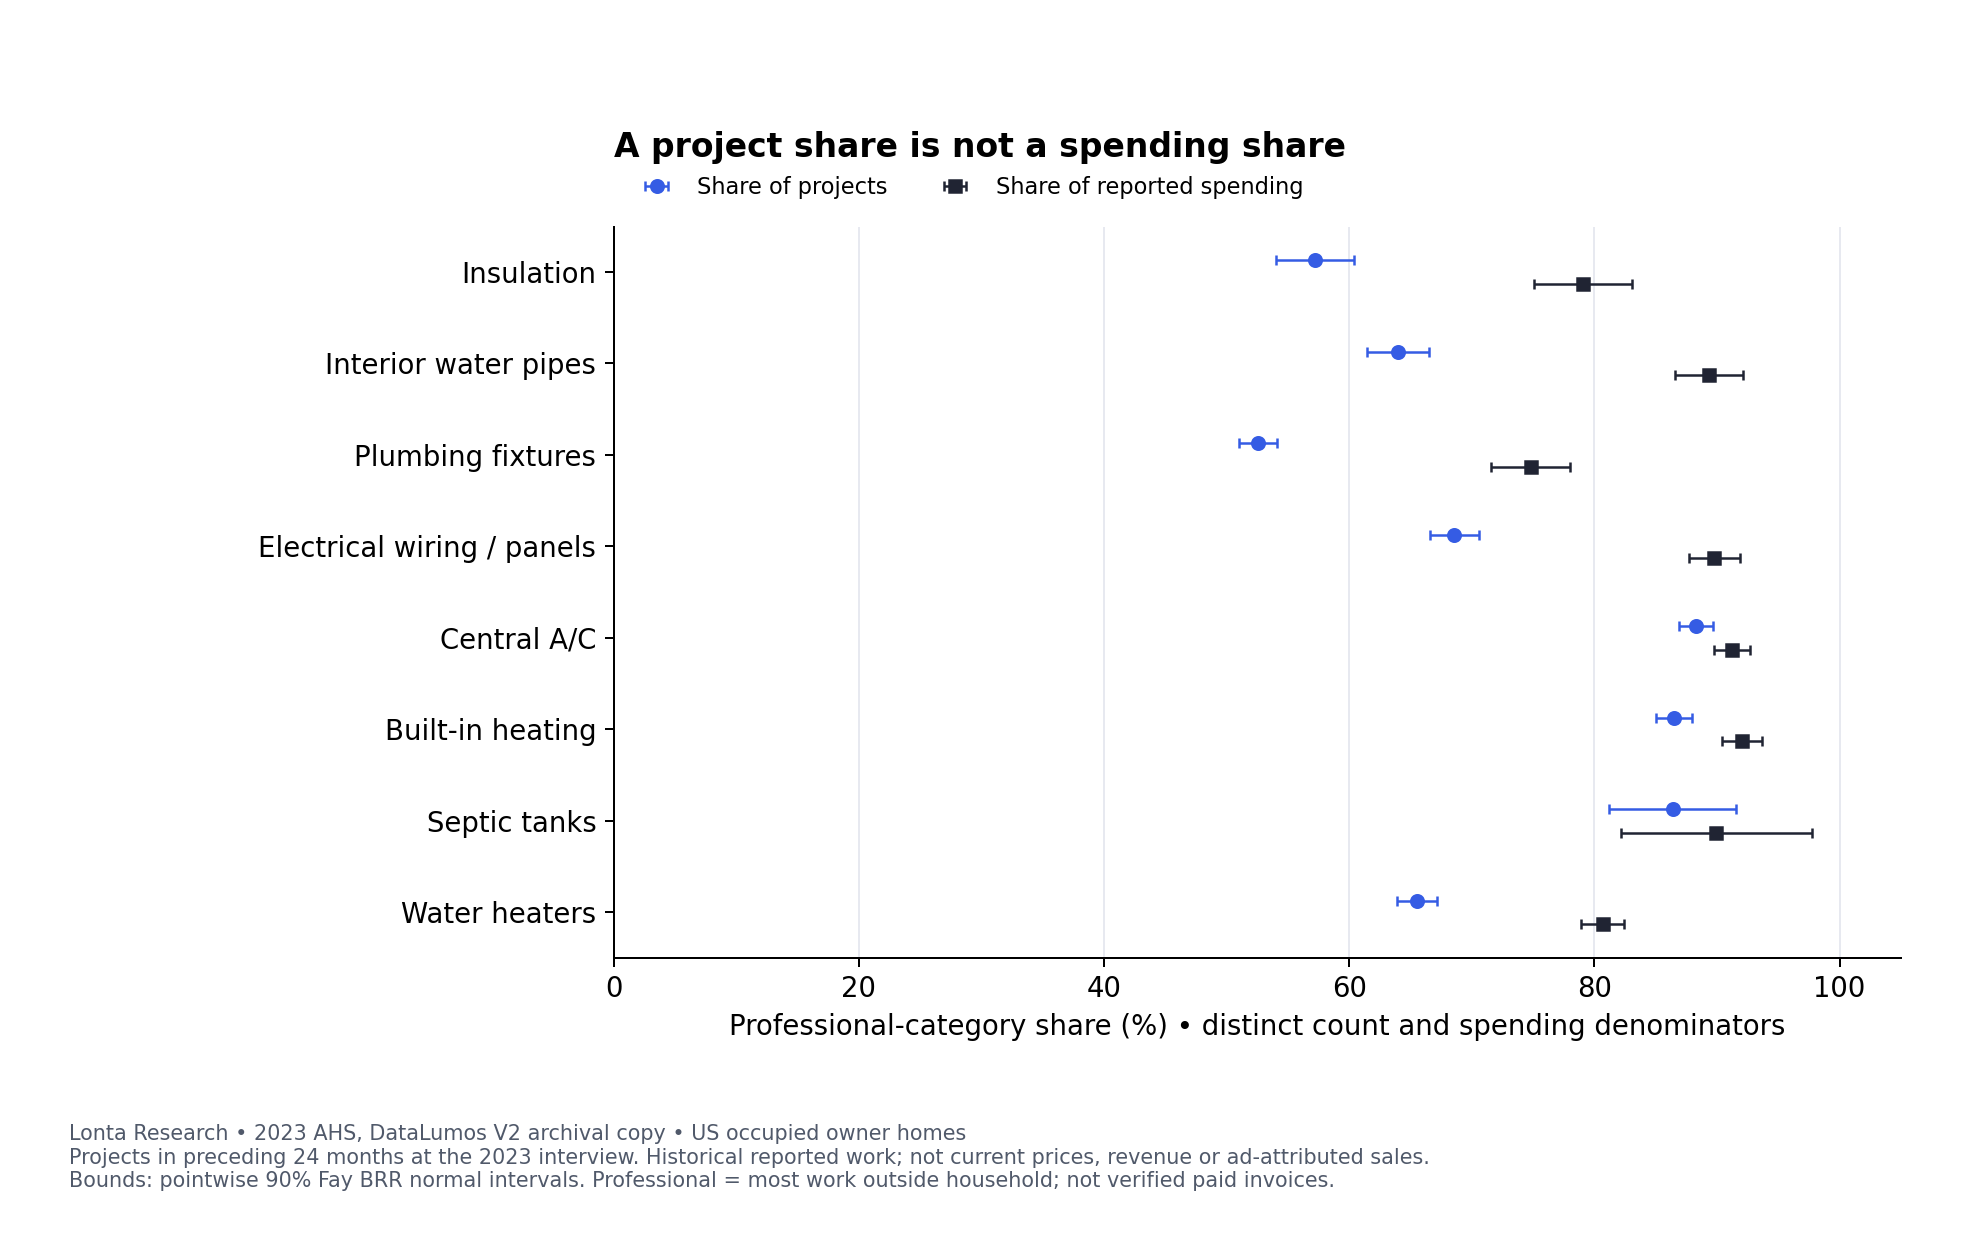

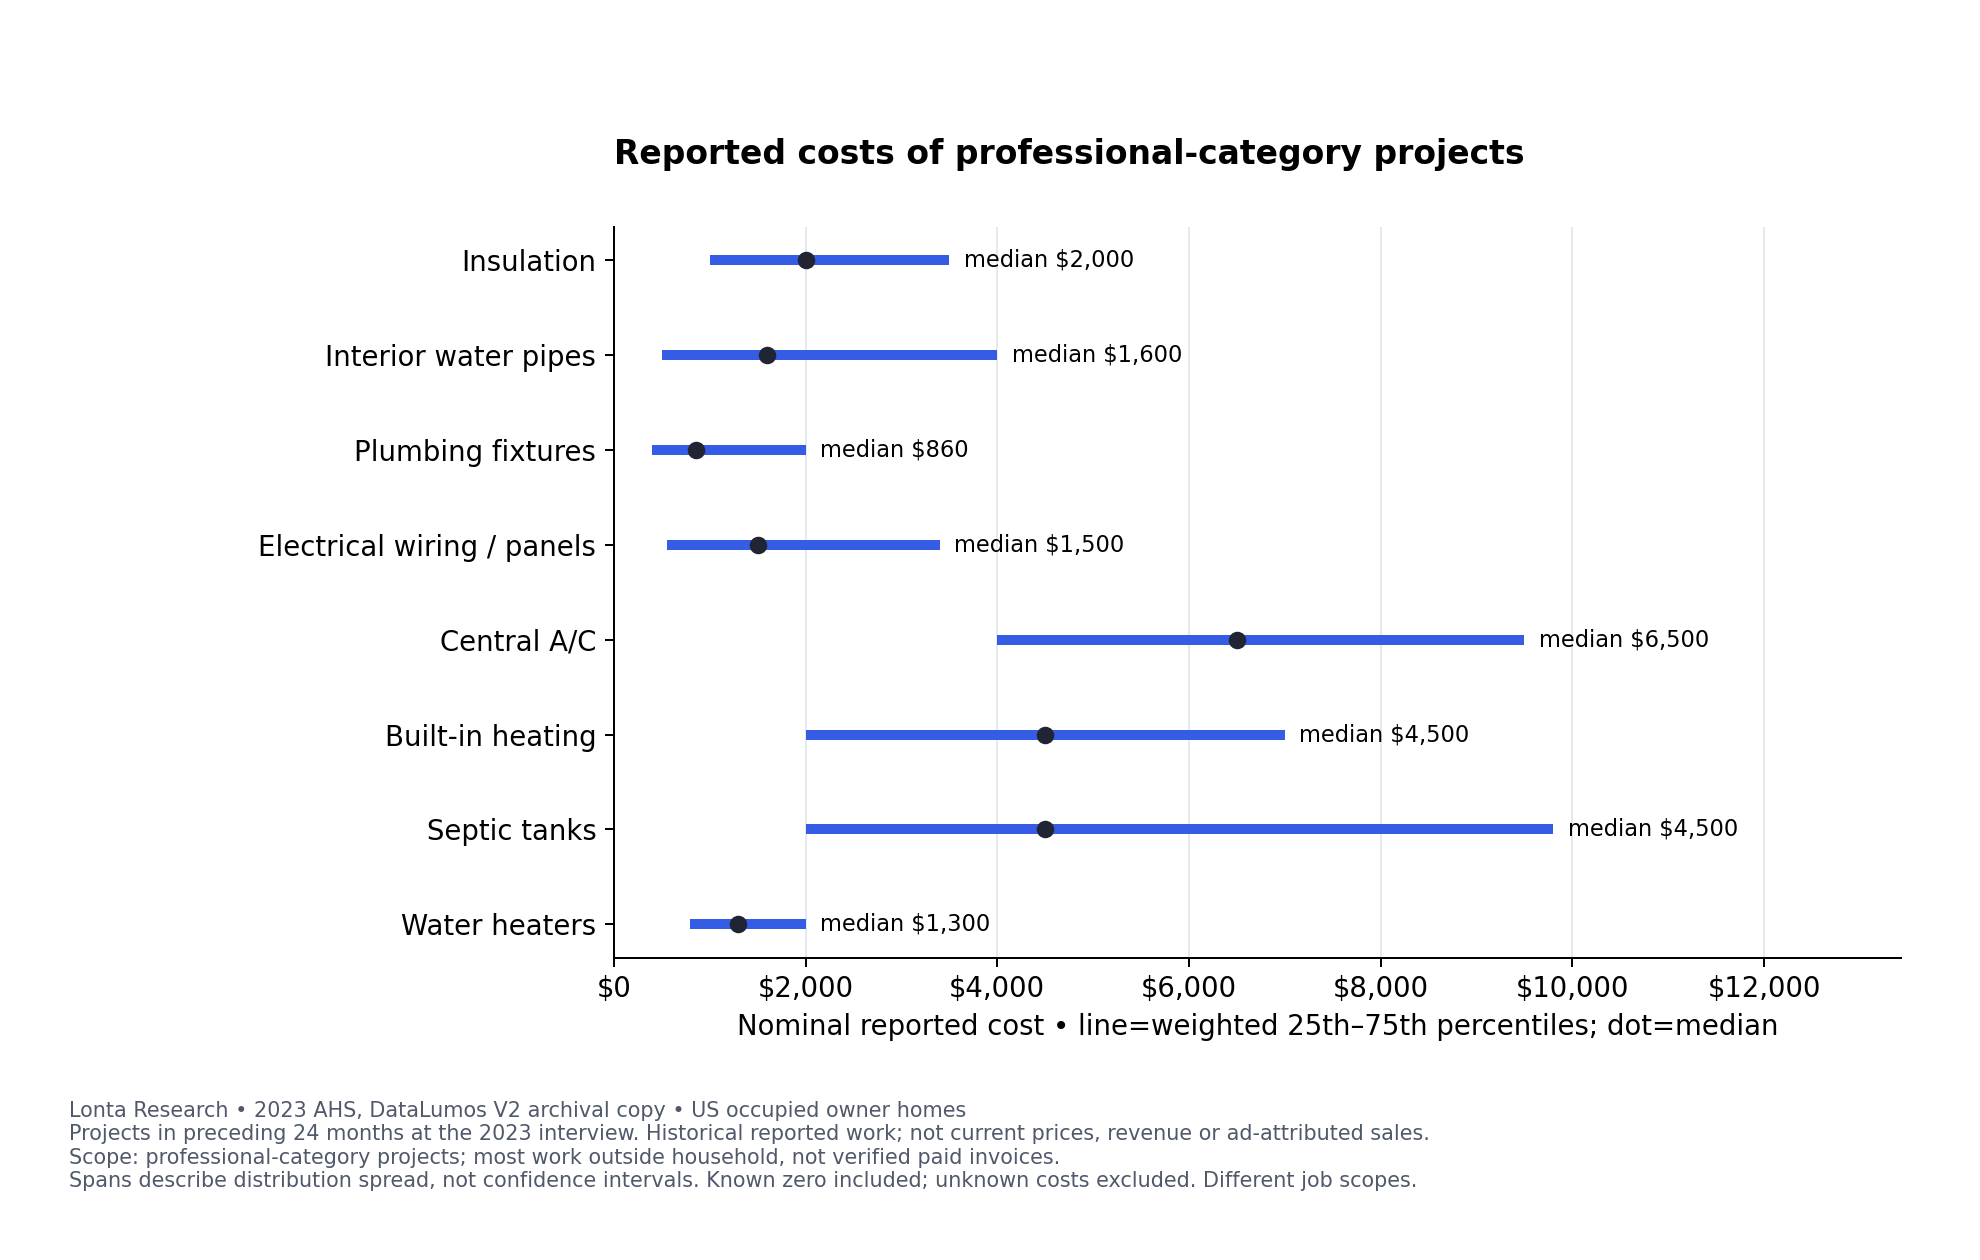

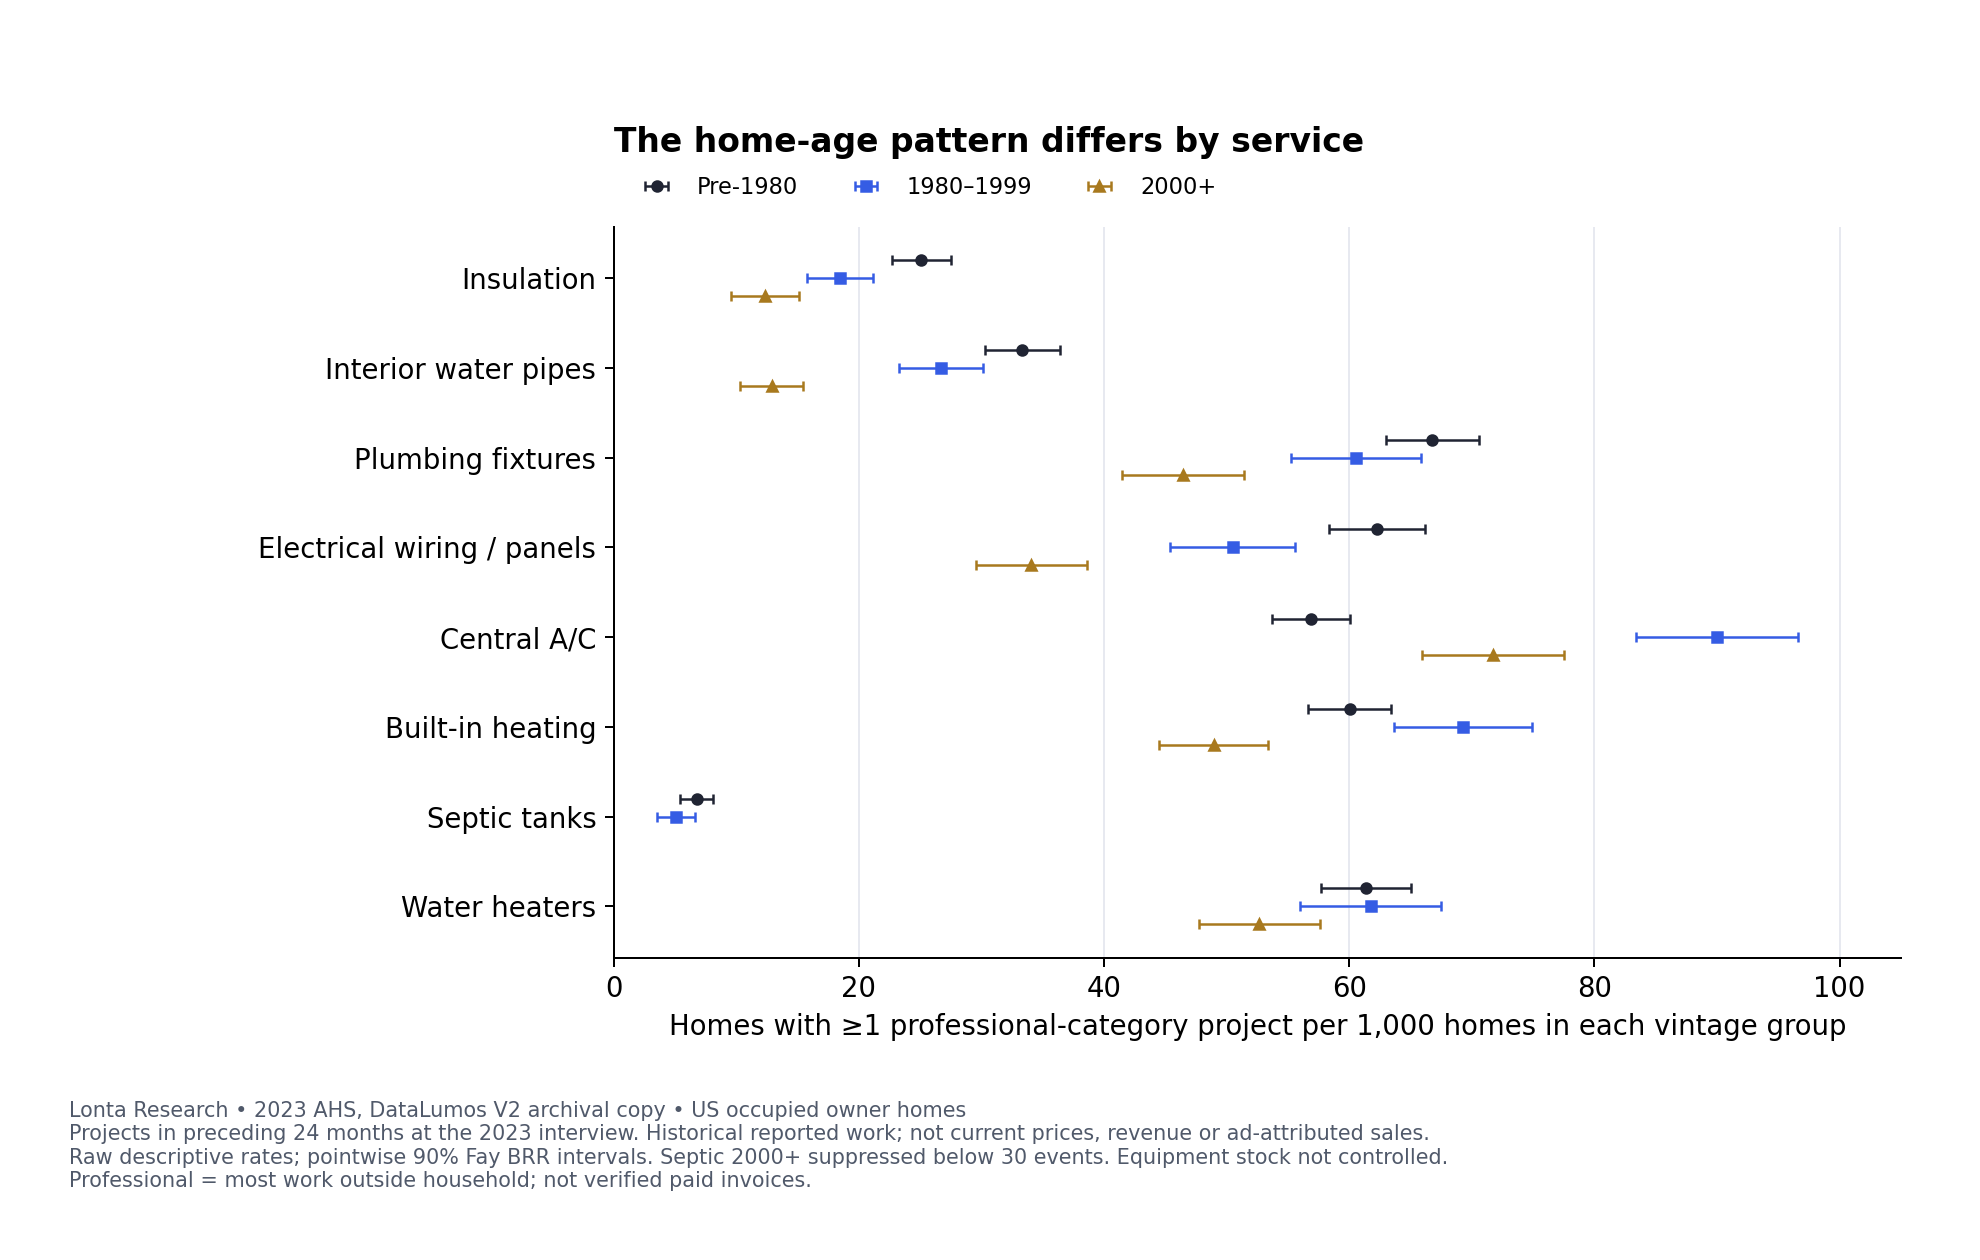

In [4]:
from render_figures import render
for name in render(data,'figures'):
    display(Image(filename=f'figures/{name}.png'))


## Takeaways
Project count, reported spending and household participation answer different questions.
House age alone is not a validated marketing rule; the observed pattern depends on service.
Use the service-mix worksheet to define a local hypothesis and collect serviceable,
quoted, accepted, completed and paid outcomes separately. A national median is not
your margin or advertising ceiling. Cite the dated survey, actual archival edition,
Lonta calculation and its limitations whenever reusing a result.
